### IND320 project work part 2
Name: Mina Johanne Askerød <br>
Date: .11.2026 <br>
GitHub link: https://github.com/Minajohanne/IND320_project_Minajohanne <br>
Streamlit link: https://ind320projectminajohanne.streamlit.app/<br>
Recording link: 


#####  Import packages 

In [ ]:
# Standard library
import time

# Data manipulation and numerical computing
import numpy as np
import pandas as pd
import geopandas as gpd

# Data retrieval and API requests
import requests
import requests_cache
import openmeteo_requests
from openmeteo_requests.Client import OpenMeteoRequestsError
from retry_requests import retry

# Statistical analysis and signal processing
import scipy.stats as stats
from scipy.fft import dct, idct
from scipy.signal import stft
from sklearn.neighbors import LocalOutlierFactor
from statsmodels.tsa.seasonal import STL

# Visualization
import matplotlib.pyplot as plt
from matplotlib.figure import Figure




Read the shapefiles corresponding to the electricity areas and precipitation areas that correspond to the Magasinstatistikk data.

In [ ]:
# Read shapefiles
gdf_nve = gpd.read_file("../data/NVE_Region") # precipitation areas 
gdf_el = gpd.read_file("../data/Budområder") # electricity areas 

,objectid,budomr,globalid,st_area(sh,st_perimet,geometry
0,1.0,NO 1,NaN,6.052902e+10,1.657761e+06,"POLYGON ((337473.63 6970542.97, 337711.9 69703..."
1,2.0,NO 2,NaN,6.875969e+10,1.256473e+06,"POLYGON ((-9833.91 6726499.86, -9836 6726404.0..."
2,3.0,NO 3,NaN,1.042199e+11,1.773323e+06,"POLYGON ((308588.7 7261519.43, 313576.63 72590..."
3,4.0,NO 4,NaN,2.032500e+11,3.385499e+06,"POLYGON ((973920.93 7962739.19, 974922.77 7962..."
4,5.0,NO 5,NaN,3.334870e+10,1.106762e+06,"POLYGON ((101466.43 6881318.54, 101525.43 6881..."


##### Function that generates K random longitude-latitude coordinate pairs within each region.


In [34]:
def generate_coordinates(
    gdf: gpd.GeoDataFrame,
    region_column: str,
    K: int = 1000
) -> dict[str, list[tuple[float, float]]]:
    """
    Generate K random longitude-latitude coordinate pairs within each region.

    The geometries are projected to EPSG:25833 before sampling to ensure
    that points are sampled using a projected coordinate system.
    The sampled points are then converted to WGS84 (EPSG:4326).

    Args:
        gdf (gpd.GeoDataFrame): GeoDataFrame containing region geometries.
        region_column (str): Name of the column containing region names.
        K (int): Number of random points to generate per region.
            Defaults to 1000.

    Returns:
        dict[str, list[tuple[float, float]]]: Dictionary mapping each
        region name to a list of (longitude, latitude) coordinate pairs.
    """

    # Project geometries to a coordinate system using metres
    gdf_projected = gdf.to_crs(epsg=25833)

    # Generate K random points within each region geometry
    points = gdf_projected.geometry.sample_points(
        size=K,
        random_state=42
    )

    # Convert sampled points to WGS84 (longitude, latitude)
    points_wgs84 = points.to_crs(epsg=4326)

    region_coordinates: dict[str, list[tuple[float, float]]] = {}

    # Extract longitude and latitude for each sampled point
    for i, multipoint in points_wgs84.items():
        region_name = gdf.loc[i, region_column]

        coordinates = [
            (point.x, point.y)
            for point in multipoint.geoms
        ]

        region_coordinates[region_name] = coordinates

    return region_coordinates


In [35]:
# Generate coordinates for NVE regions
nve_coordinates = generate_coordinates(
    gdf_nve,
    region_column="REGION"
)

# Generate coordinates for electricity areas
el_coordinates = generate_coordinates(
    gdf_el,
    region_column="budomr"
)

In [36]:
print(f"Precipitation areas: {', '.join(nve_coordinates.keys())}")
print(f"Electricity areas: {', '.join(el_coordinates.keys())}")

Precipitation areas: RV, RM, RN, RÃ, RS
Electricity areas: NO 1, NO 2, NO 3, NO 4, NO 5


##### Function that retrieves hourly historical reanalysis data from open-meteo API using the ERA5 model for a single location. 

In [38]:
def get_weather_data(region: str,
                    start_date: str, 
                    end_date: str
                    ) -> pd.DataFrame:
    """
    Download hourly historical weather data from the Open-Meteo API using the ERA5 model.

    Retrieves temperature and precipitation data for 1000 randomly sampled
    locations within the specified region and calculates the hourly average
    across all locations.

    Args:
        region (str): Region identifier, e.g. "NO 3".
        start_date (str): Start date in YYYY-MM-DD format.
        end_date (str): End date in YYYY-MM-DD format.

    Returns:
        pd.DataFrame: DataFrame containing hourly timestamps, average temperature
        (°C), and average precipitation (mm) for the selected region.
    """
    # Setup Open-Meteo API client
    cache_session = requests_cache.CachedSession(".cache", expire_after=-1)
    retry_session = retry(cache_session, retries=5, backoff_factor=0.2)
    openmeteo = openmeteo_requests.Client(session=retry_session)

    # Get coordinates for the selected region
    lon = [lon for lon, lat in el_coordinates[region]]
    lat = [lat for lon, lat in el_coordinates[region]]

    # API URL
    url = "https://archive-api.open-meteo.com/v1/archive"

    # Store data for each location
    dataframes = []
    batch_size = 10

    # Download weather data in batches
    for i in range(0, len(lat), batch_size):

        lat_batch = lat[i:i + batch_size]
        lon_batch = lon[i:i + batch_size]

        # API parameters
        params = {
            "latitude": lat_batch,
            "longitude": lon_batch,
            "start_date": start_date,
            "end_date": end_date,
            "hourly": ["temperature_2m", "precipitation"],
            "models": "era5",
        }

        # Download weather data
        while True:
            try:
                responses = openmeteo.weather_api(url, params=params)
                break

            except OpenMeteoRequestsError as e:
                if "Minutely API request limit exceeded" in str(e):
                    print("API limit reached. Waiting 60 seconds...")
                    time.sleep(60)
                else:
                    raise

        # Process data for each location
        for response in responses:
            hourly = response.Hourly()

            temperature = hourly.Variables(0).ValuesAsNumpy()
            precipitation = hourly.Variables(1).ValuesAsNumpy()

            dates = pd.date_range(
                start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
                end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
                freq=pd.Timedelta(seconds=hourly.Interval()),
                inclusive="left"
            )

            df = pd.DataFrame({
                "date": dates,
                "temperature_2m": temperature,
                "precipitation": precipitation
            })

            dataframes.append(df)

        print(f"Downloaded {min(i + batch_size, len(lat))}/{len(lat)} locations")

    # Combine all locations
    weather_data = pd.concat(dataframes, ignore_index=True)

    # Calculate hourly averages across the region
    regional_average = (
        weather_data
        .groupby("date")[["temperature_2m", "precipitation"]]
        .mean()
        .reset_index()
    )

    return regional_average


In [43]:
# downloading data for NO3 in 2024
weather_no3 = get_weather_data(
    region="NO 3",
    start_date="2024-01-01",
    end_date="2024-12-31"
)

weather_no3.head()

Downloaded 10/1000 locations
Downloaded 20/1000 locations
Downloaded 30/1000 locations
Downloaded 40/1000 locations
Downloaded 50/1000 locations
Downloaded 60/1000 locations
Downloaded 70/1000 locations
Downloaded 80/1000 locations
Downloaded 90/1000 locations
Downloaded 100/1000 locations
Downloaded 110/1000 locations
Downloaded 120/1000 locations
Downloaded 130/1000 locations
Downloaded 140/1000 locations
Downloaded 150/1000 locations
Downloaded 160/1000 locations
Downloaded 170/1000 locations
Downloaded 180/1000 locations
Downloaded 190/1000 locations
Downloaded 200/1000 locations
Downloaded 210/1000 locations
Downloaded 220/1000 locations
Downloaded 230/1000 locations
Downloaded 240/1000 locations
Downloaded 250/1000 locations
Downloaded 260/1000 locations
Downloaded 270/1000 locations
Downloaded 280/1000 locations
Downloaded 290/1000 locations
Downloaded 300/1000 locations
Downloaded 310/1000 locations
Downloaded 320/1000 locations
Downloaded 330/1000 locations
Downloaded 340/1000

,date,temperature_2m,precipitation
0,2024-01-01 00:00:00+00:00,-3.480681,0.0028
1,2024-01-01 01:00:00+00:00,-3.618031,0.0024
2,2024-01-01 02:00:00+00:00,-3.596881,0.0023
3,2024-01-01 03:00:00+00:00,-3.630831,0.0023
4,2024-01-01 04:00:00+00:00,-3.581631,0.0022


In [44]:
# dimensions of the dataframe
weather_no3.shape 

(8784, 3)

Plot of the average precipitation as a function of time.

##### Function that applies DCT high-pass filtering and robust SPC to identify precipitation outliers. 

In [51]:
def plot_precipitation_spc(
    df: pd.DataFrame,
    cutoff_period: int = 168,
    n_std: float = 3.0
) -> tuple[Figure, pd.DataFrame]:
    """
    Plot hourly precipitation with robust SPC control limits.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame containing date and precipitation columns.
    cutoff_period : int, default=168
        Cutoff period in hours (168 hours = 7 days).
    n_std : float, default=3.0
        Number of robust standard deviations used for control limits.

    Returns
    -------
    tuple[Figure, pd.DataFrame]
        Matplotlib figure and a summary of detected outliers.
    """
    # Extract precipitation and dates
    precipitation = df["precipitation"].to_numpy()
    dates = df["date"]

    # Apply DCT high-pass filtering
    N = len(precipitation)
    W = np.linspace(0, 0.5, N)
    cutoff = 1 / cutoff_period

    dct_signal = dct(precipitation, type=1, norm="forward")
    filtered_dct = dct_signal.copy()
    filtered_dct[W < cutoff] = 0

    filtered = idct(filtered_dct, type=1, norm="forward")

    # Calculate robust statistics using median and MAD
    median = np.median(filtered)
    mad = np.median(np.abs(filtered - median))
    robust_std = 1.4826 * mad

    ucl = median + n_std * robust_std
    lcl = median - n_std * robust_std

    # Identify outliers in the filtered signal
    outliers = (filtered > ucl) | (filtered < lcl)

    # Convert SPC limits to the original precipitation scale
    trend = precipitation - filtered
    upper_boundary = trend + ucl
    lower_boundary = np.maximum(trend + lcl, 0)

    # Plot precipitation and control limits
    fig, ax = plt.subplots(figsize=(12, 5))

    ax.plot(
        dates, precipitation,
        color="steelblue",
        linewidth=0.8,
        label="Average precipitation"
    )

    ax.plot(
        dates, upper_boundary,
        "r--",
        label="Upper control limit"
    )

    ax.plot(
        dates, lower_boundary,
        "r--",
        label="Lower control limit"
    )

    ax.scatter(
        dates[outliers],
        precipitation[outliers],
        color="darkorange",
        s=15,
        label="Outliers",
        zorder=3
    )

    ax.set_title("Average Precipitation with SPC Limits (NO3, 2024)")
    ax.set_xlabel("Date")
    ax.set_ylabel("Average precipitation (mm)")
    ax.legend()
    ax.grid(alpha=0.3)

    fig.tight_layout()

    # Create outlier summary table
    outlier_summary = pd.DataFrame({
        "Metric": [
            "Total observations",
            "Number of outliers",
            "Percentage of outliers (%)",
            "Maximum outlier precipitation (mm)"
        ],
        "Value": [
            len(precipitation),
            int(outliers.sum()),
            round(outliers.mean() * 100, 2),
            round(float(precipitation[outliers].max()), 3)
            if outliers.any() else np.nan
        ]
    })

    return fig, outlier_summary


,Metric,Value
0,Total observations,8784.000
1,Number of outliers,550.000
2,Percentage of outliers (%),6.260
3,Maximum outlier precipitation (mm),2.751


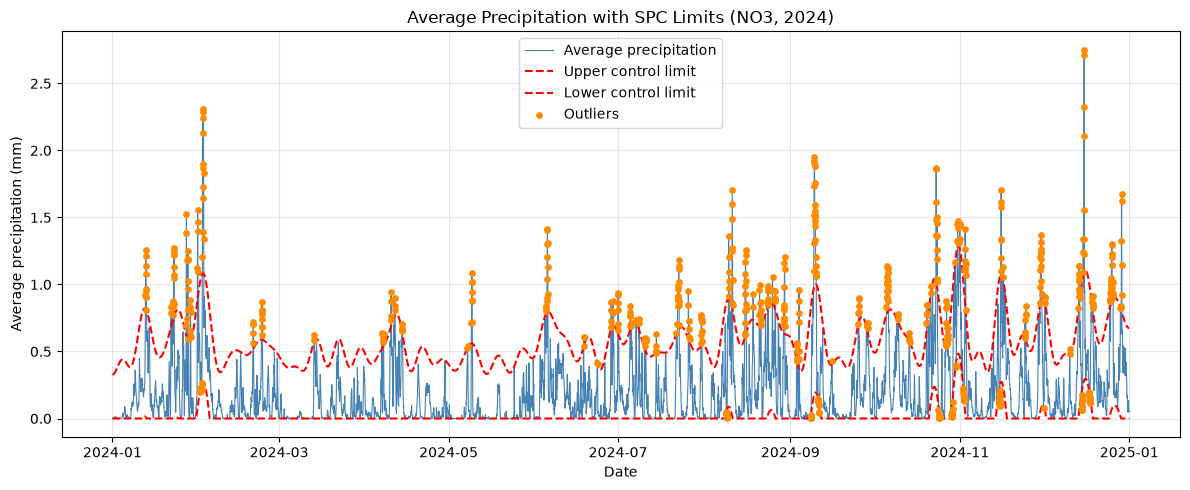

In [52]:
# test the function 
fig, summary = plot_precipitation_spc(weather_no3)

display(summary)
plt.show()

The plot shows the original hourly precipitation in NO3 during 2024, together with SPC control limits calculated using robust statistics from the high-pass filtered data. The plot is generated using the default parameter values of 3 standard deviations and a cutoff period of 168 hours (7 days). The orange points represent observations identified as outliers. Several observations exceed the upper control limit, particularly during the second half of the year.

,Metric,Value
0,Total observations,8784.000
1,Number of outliers,978.000
2,Percentage of outliers (%),11.130
3,Maximum outlier precipitation (mm),2.751


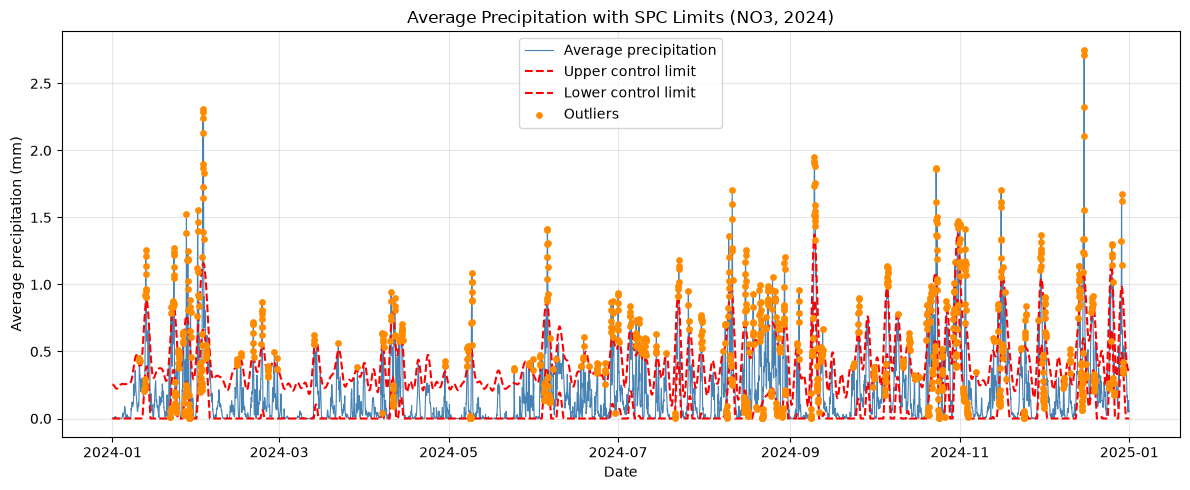

In [53]:
# Test with different parameters
fig, summary = plot_precipitation_spc(
    weather_no3,
    cutoff_period=72,
    n_std=2.5
)

display(summary)
plt.show()

The plot shows the original hourly precipitation in NO3 during 2024, together with SPC control limits calculated using robust statistics from the high-pass filtered data. This plot is generated using a cutoff period of 72 hours (3 days) and 2.5 standard deviations, instead of the default values. The orange points represent observations identified as outliers. Compared to the previous plot, more observations are classified as outliers, particularly during the second half of the year. This is mainly due to the lower number of standard deviations, which results in narrower control limits.

##### Function that applies Local Outlier Factor (LOF) to detect and visualize temperature outliers.

In [57]:
def plot_temperature_lof(
    df: pd.DataFrame,
    contamination: float = 0.01,
    n_neighbors: int = 20
) -> tuple[Figure, pd.DataFrame]:
    """
    Detect temperature outliers using Local Outlier Factor (LOF).

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame containing date and temperature_2m columns.
    contamination : float
        Expected proportion of outliers (default: 0.01).
    n_neighbors : int
        Number of nearest neighbors used by LOF (default: 20).

    Returns
    -------
    tuple[Figure, pd.DataFrame]
        Matplotlib figure and a summary table of detected outliers.
    """

    # Extract temperature as a 2D array
    temp = df[["temperature_2m"]].to_numpy()

    # Apply Local Outlier Factor
    lof = LocalOutlierFactor(
        n_neighbors=n_neighbors,
        contamination=contamination
    )

    pred_labels = lof.fit_predict(temp)

    # Identify outliers
    outliers = pred_labels == -1

    # Plot temperature and highlight outliers
    fig, ax = plt.subplots(figsize=(12, 5))

    ax.plot(
        df["date"],
        df["temperature_2m"],
        color="steelblue",
        linewidth=0.8,
        label="Average temperature"
    )

    ax.scatter(
        df.loc[outliers, "date"],
        df.loc[outliers, "temperature_2m"],
        color="darkorange",
        s=20,
        label="Outliers",
        zorder=3
    )

    ax.set_title("Average Temperature with LOF Outliers (NO3, 2024)")
    ax.set_xlabel("Date")
    ax.set_ylabel("Temperature (°C)")
    ax.legend()
    ax.grid(alpha=0.3)

    fig.tight_layout()

    # Create outlier summary table
    outlier_summary = pd.DataFrame({
        "Metric": [
            "Total observations",
            "Number of outliers",
            "Percentage of outliers (%)",
            "Minimum outlier temperature (°C)",
            "Maximum outlier temperature (°C)"
        ],
        "Value": [
            len(df),
            int(outliers.sum()),
            round(outliers.mean() * 100, 2),
            round(float(temp[outliers].min()), 2)
            if outliers.any() else np.nan,
            round(float(temp[outliers].max()), 2)
            if outliers.any() else np.nan
        ]
    })

    return fig, outlier_summary

,Metric,Value
0,Total observations,8784.00
1,Number of outliers,88.00
2,Percentage of outliers (%),1.00
3,Minimum outlier temperature (°C),-9.73
4,Maximum outlier temperature (°C),20.75


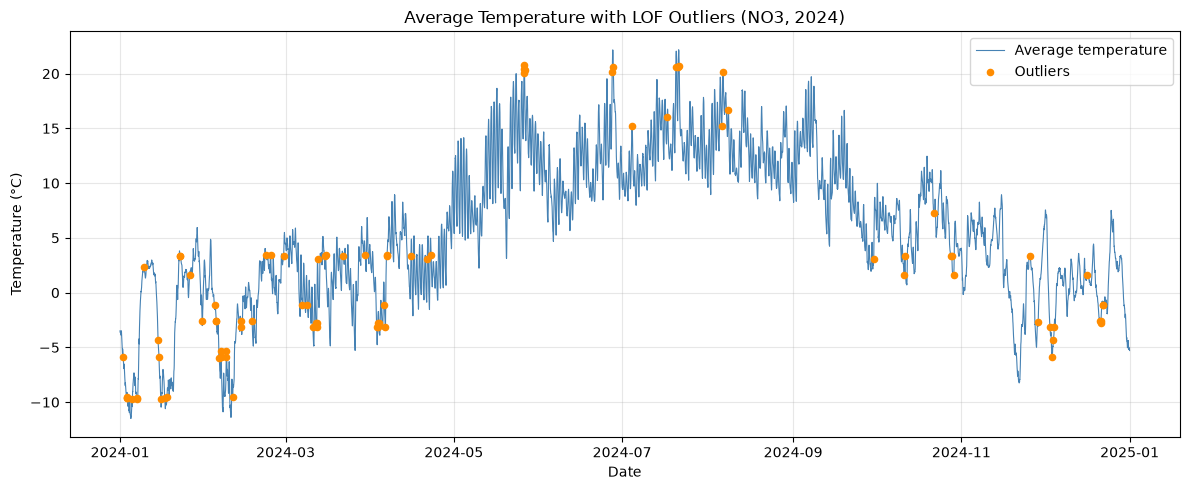

In [58]:
# testing the function with default values
fig, summary = plot_temperature_lof(weather_no3)

display(summary)
plt.show()

The plot shows the average hourly temperature in NO3 during 2024, with outliers identified using the Local Outlier Factor (LOF) method. The analysis uses the default parameter values of 0.01 for contamination and 20 nearest neighbors. The orange points represent observations identified as outliers, which occur throughout the year, particularly during winter and summer. The summary table shows that 88 out of 8,784 observations (1%) were classified as outliers, with temperatures ranging from -9.73°C to 20.75°C. The percentage of outliers is consistent with the contamination parameter of 0.01, which specifies the expected proportion of outliers.

,Metric,Value
0,Total observations,8784.00
1,Number of outliers,176.00
2,Percentage of outliers (%),2.00
3,Minimum outlier temperature (°C),-11.49
4,Maximum outlier temperature (°C),20.75


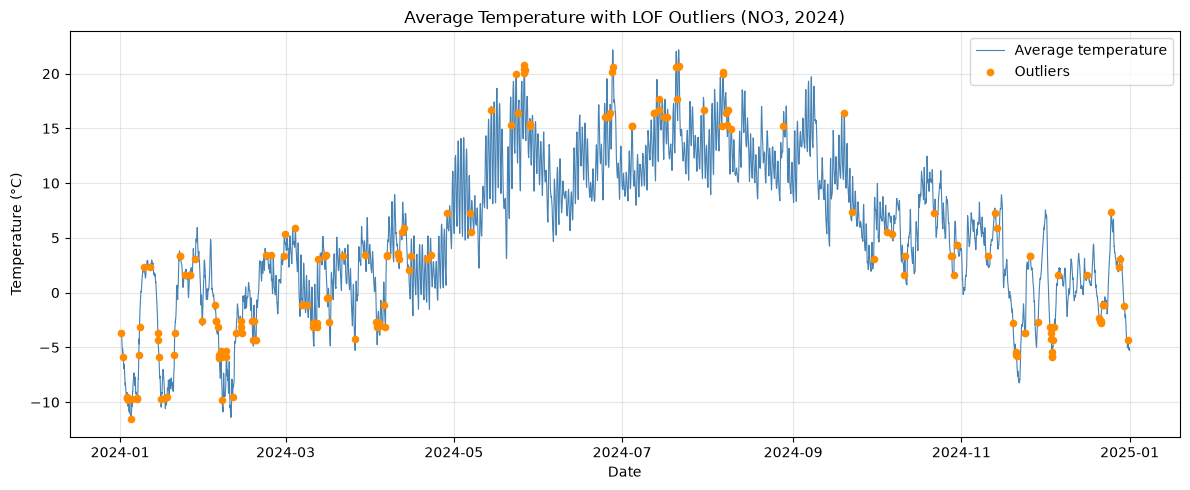

In [ ]:
# testing the function with other parameters
fig, summary = plot_temperature_lof(
    weather_no3,
    contamination=0.02
)

display(summary)
plt.show()

The plot shows the average hourly temperature in NO3 during 2024, with outliers identified using the Local Outlier Factor (LOF) method. This plot is generated using a contamination value of 0.02 and 20 nearest neighbors. The orange points represent observations identified as outliers, which occur throughout the year, particularly during winter and summer. The summary table shows that 176 out of 8,784 observations (2%) were classified as outliers, with temperatures ranging from -11.49°C to 20.75°C. Compared to the previous plot, more observations are identified as outliers due to the increased contamination parameter, which specifies a higher expected proportion of outliers.

##### STL on the degree of filling from the magasinstatistikk data. 

In [59]:
# retrieving data from magasinstatistikk using an API 
url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"
response = requests.get(url)
print(response)


<Response [200]>


In [61]:
# converting the data to pandas dataframe and filtering the data for Norway
data = response.json()
df = pd.DataFrame(data)
df_norway = df[
    (df["omrType"] == "NO") &
    (df["omrnr"] == 0)
].copy()
df_norway["dato_Id"] = pd.to_datetime(df_norway["dato_Id"])
df_norway = (
    df_norway
    .sort_values("dato_Id")
    .reset_index(drop=True))
df_norway.head()

,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-01-08,NO,0,1995,1,0.607988,87.43758,53.161003,0001-01-01T00:00:00,0.752631,-0.144643
1,1995-01-15,NO,0,1995,2,0.582088,87.43758,50.896374,0001-01-01T00:00:00,0.607988,-0.025900
2,1995-01-22,NO,0,1995,3,0.562121,87.43758,49.150486,0001-01-01T00:00:00,0.582088,-0.019967
3,1995-01-29,NO,0,1995,4,0.534222,87.43758,46.711033,0001-01-01T00:00:00,0.562121,-0.027899
4,1995-02-05,NO,0,1995,5,0.506221,87.43758,44.262720,0001-01-01T00:00:00,0.534222,-0.028001


Function that applies STL decomposition on weekly reservoir filling levels. 

In [64]:
def plot_stl(
    data: pd.DataFrame,
    seasonal: int = 13,
    trend: int = 105,
    robust: bool = True
) -> Figure:
    """
    Perform STL decomposition on weekly reservoir filling levels.

    Parameters
    ----------
    data : pd.DataFrame
        DataFrame containing weekly filling levels.
    seasonal : int, default=13
        Length of the seasonal LOESS smoother.
    trend : int, default=105
        Length of the trend LOESS smoother.
    robust : bool, default=True
        Whether to use robust fitting to reduce the effect of outliers.

    Returns
    -------
    Figure
        Matplotlib figure showing the STL decomposition.
    """
    stl = STL(
        data["fyllingsgrad"],
        period=52,
        seasonal=seasonal,
        trend=trend,
        robust=robust
    )

    result = stl.fit()
    fig = result.plot()

    return fig

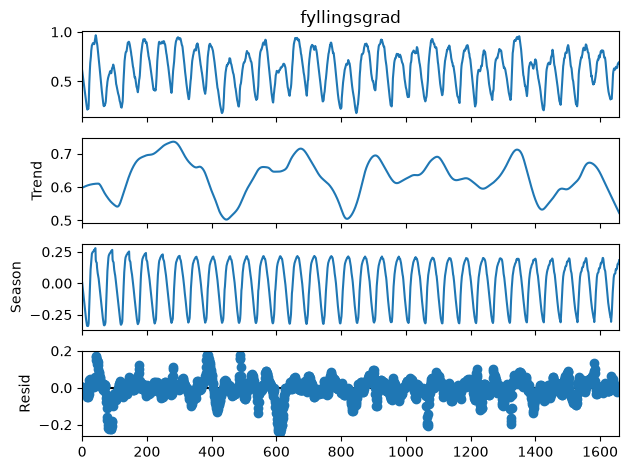

In [65]:
# test the function with default parameters 
fig = plot_stl(df_norway)
plt.show()

The plot shows the STL decomposition of weekly reservoir filling levels in Norway, using the default parameter values of 13 for the seasonal smoother, 105 for the trend smoother, and robust=True. The original time series shows a clear seasonal pattern, with filling levels increasing and decreasing throughout the year. The trend component shows longer-term variations in filling levels, while the seasonal component captures the regular annual fluctuations. The residual component represents the remaining variation that is not explained by the trend or seasonal components. Overall, the decomposition shows that reservoir filling levels have a strong and relatively stable seasonal pattern.

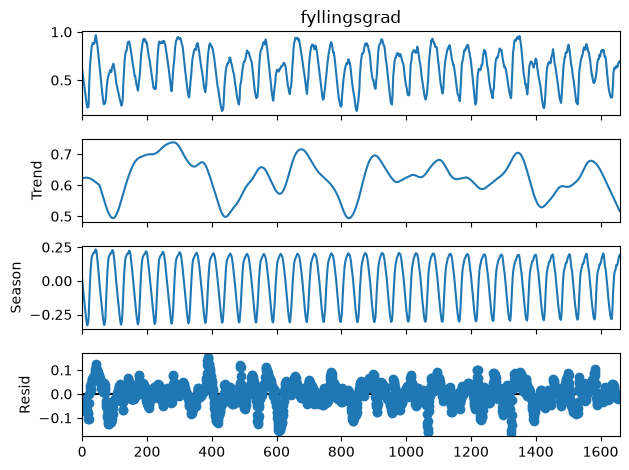

In [62]:
# test the function with other parameters 
fig = plot_stl(
    df_norway,
    seasonal=21,
    trend=107,
    robust=False
)
plt.show()

The plot shows the STL decomposition of weekly reservoir filling levels in Norway, using a seasonal smoother of 21, a trend smoother of 107, and robust=False. The original time series still shows a clear annual seasonal pattern, with regular increases and decreases in filling levels. The trend component captures longer-term variations, while the seasonal component shows relatively stable annual fluctuations. Compared to the previous plot using default parameters, the overall decomposition remains similar, but the residual component shows some differences. One reason is that robust fitting is disabled (robust=False), meaning that extreme observations are no longer given less weight during the decomposition. As a result, unusually high or low filling levels may have a greater influence on the estimated trend and seasonal components, rather than remaining in the residuals.

##### Function that creates a spectrogram on the degree of filling from the magasinstatistikk data. 

In [ ]:
def plot_spectrogram(
    data: pd.DataFrame,
    nperseg: int = 104,
    noverlap: int = 52
) -> Figure:
    """
    Create a spectrogram of weekly reservoir filling levels.

    Parameters
    ----------
    data : pd.DataFrame
        DataFrame containing weekly filling levels.
    nperseg : int, default=104
        Window length in weeks.
    noverlap : int, default=52
        Number of overlapping observations between windows.

    Returns
    -------
    Figure
        Matplotlib figure showing the spectrogram.
    """
    # Extract filling levels
    y = data["fyllingsgrad"].to_numpy()

    # Compute short-time Fourier transform
    f, t, Zxx = stft(
        y,
        fs=1,
        nperseg=nperseg,
        noverlap=noverlap
    )

    # Create spectrogram
    fig, ax = plt.subplots(figsize=(12, 5))

    mesh = ax.pcolormesh(
        t,
        f,
        np.abs(Zxx),
        shading="auto"
    )

    ax.set_title("Spectrogram of reservoir filling levels")
    ax.set_xlabel("Time (weeks)")
    ax.set_ylabel("Frequency (cycles/week)")

    fig.colorbar(mesh, ax=ax, label="Magnitude")

    return fig

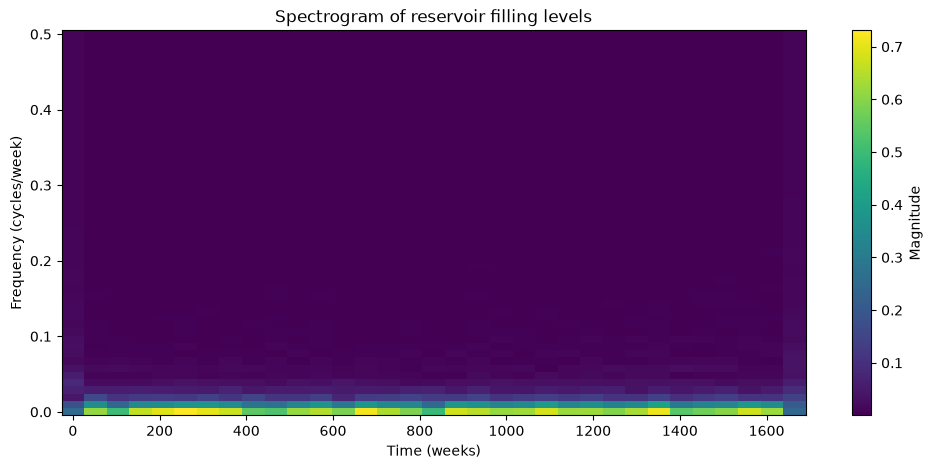

In [ ]:
# test the spectrogram with default values
fig = plot_spectrogram(df_norway)
plt.show()

The plot shows the spectrogram of weekly reservoir filling levels in Norway, using the default window length of 104 weeks and an overlap of 52 weeks. The x-axis represents time in weeks, while the y-axis represents frequency in cycles per week. The colour scale indicates the magnitude of the frequency components, with brighter colours representing stronger signals. Most of the energy is concentrated at low frequencies, indicating that reservoir filling levels are dominated by slow variations and seasonal patterns. The strong signal near zero frequency is mainly due to the overall filling level and long-term variations. Higher frequencies have much lower magnitudes, suggesting that rapid fluctuations contribute less to the overall variation in reservoir filling levels.

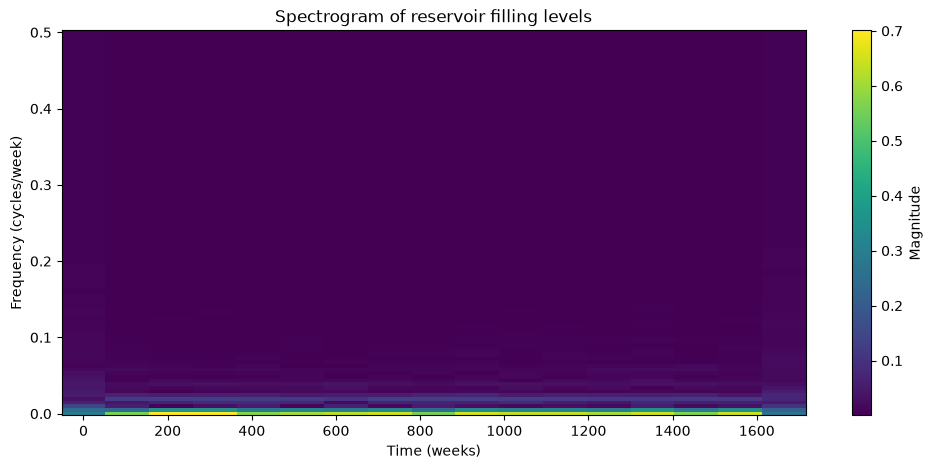

In [ ]:
# test the spectrogram with different window length and overlap values
fig = plot_spectrogram(
    df_norway,
    nperseg=208,
    noverlap=104
)
plt.show()

The plot shows the spectrogram of weekly reservoir filling levels in Norway, using a window length of 208 weeks (4 years) and an overlap of 104 weeks (2 years), instead of the default values. Compared to the previous spectrogram, the overall frequency pattern remains similar, with most of the energy concentrated at low frequencies. The longer window length provides better frequency resolution, making it easier to distinguish between nearby frequencies, but reduces the ability to detect changes over shorter time periods. The spectrogram still shows that low-frequency variations dominate the reservoir filling levels, while higher-frequency fluctuations have relatively low magnitudes.

#### Log (description of compulsory work)

- laste ned værdata fra openmeteo - løkke over responses og batchwise 
Kort oppsummert: Du bruker batching for å kunne laste ned dataene uten å sende for store forespørsler, og du looper over responsene fordi hver respons inneholder værdata for én lokasjon. Til slutt kombinerer du dataene og beregner gjennomsnittet for hele regionen.

**Batching:** I download the weather data in batches of 10 locations to avoid sending too many coordinates in a single API request. Sending all 1000 coordinates at once results in a URL that is too long for the server to handle (HTTP 414).

**While loop and error handling:** I use a `while` loop with `try`/`except` to handle API rate limits. If the API returns an error because the number of requests per minute has been exceeded, the program waits 60 seconds before trying again. This allows the download to continue without stopping due to temporary rate-limit errors.


#### Description of AI usage
